# Analyse Dataset's Data and graphics


In [2]:
from src.data.dataset_aprdb import AprdbDataset
import src.config

import pandas as pd
from src.data_analyse.aprb_analyse.aprb_utils import *

cfg = {
    "conference": None,
    "date": None,
    "keep_meta": True,
    "split": "test",
    "subset_size": 2000,
    "seed": 42
}

/home/cyaiche/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-02-09 10:27:07.808 | INFO     | src.config:<module>:12 - PROJ_ROOT path is: /home/cyaiche/openturingbench_base
2026-02-09 10:27:07.813 | INFO     | src.config:<module>:36 - MLFLOW URI path is: file:///data2/cyaiche/mlflow_root/mlruns


In [3]:
dataset = AprdbDataset(config=cfg, keep_meta=True)

In [4]:
type(dataset.data)
print(len(dataset.data))

1981


In [6]:
dataset[5]

{'label': 1,
 'content': 'Overall, this paper presents a well-designed and effective approach to video instance segmentation. The use of Inter-frame Communication Transformers (IFC) is a key innovation that enables efficient communication between frames while reducing computational overhead. The authors provide a thorough analysis of the benefits and limitations of their approach, including ablation studies and comparisons to other state-of-the-art methods. The writing is clear and concise, and the paper is well-organized and easy to follow. The experimental results are impressive, demonstrating the effectiveness of the proposed method on challenging datasets. The authors also discuss potential future directions for their work, including integrating temporal information to further improve performance.',
 'subset': 'test',
 'generator': 'llama',
 'conference': 'NeurIPS',
 'year': '2021',
 'file': 'test/llama/NeurIPS2021.test.llama-3.1-70b.csv'}

In [4]:
basic_auditw = basic_audit(dataset)

In [5]:
print(basic_auditw['flags_for_label'][0]['bullet'])
print(basic_auditw['flags_for_label'][1]['bullet'])

344
758


In [6]:
basic_auditw

{'N': 1981,
 'label_counts': {0: 981, 1: 1000},
 'flags_for_label': {0: {'empty': 0,
   'url': 61,
   'bullet': 344,
   'multi_newlines': 123,
   'bracket_refs': 150,
   'length_content': [2895,
    2270,
    3246,
    3066,
    515,
    2436,
    3088,
    1681,
    542,
    944,
    2419,
    1854,
    3631,
    1208,
    3697,
    2809,
    2616,
    776,
    2878,
    1523,
    3743,
    3715,
    1345,
    2508,
    3322,
    1269,
    3667,
    2078,
    4253,
    2395,
    1853,
    1817,
    3299,
    1188,
    966,
    1499,
    1174,
    2800,
    2032,
    1529,
    1599,
    1423,
    2944,
    1479,
    4242,
    606,
    2353,
    4293,
    6668,
    1674,
    1631,
    1346,
    1752,
    791,
    1392,
    2325,
    1025,
    2616,
    1713,
    1440,
    4900,
    1597,
    813,
    1498,
    1534,
    1520,
    2121,
    1973,
    1401,
    3074,
    4583,
    1648,
    3422,
    2238,
    1560,
    362,
    1761,
    472,
    3868,
    1919,
    863,
    4598,
    28

In [7]:
def display_histogram_(list_plot_data: List[PlotData]):
    colors = ['crimson', 'teal']
    xmin = min(min(d.values) for d in list_plot_data)
    xmax = max(max(d.values) for d in list_plot_data)

    bins = np.linspace(xmin, xmax, int(np.sqrt(len(list_plot_data[0].values))))  # ajuste 60 si besoin

    plt.figure()
    for i,p in enumerate(list_plot_data):
        plt.hist(p.values, bins=bins, alpha=0.5, label=p.label, color=colors[int(i) % len(colors)])

    plt.xlabel("Length (words)")
    plt.ylabel("Count")
    plt.yscale("log")
    plt.title("Histogrammes superposés des longueurs")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

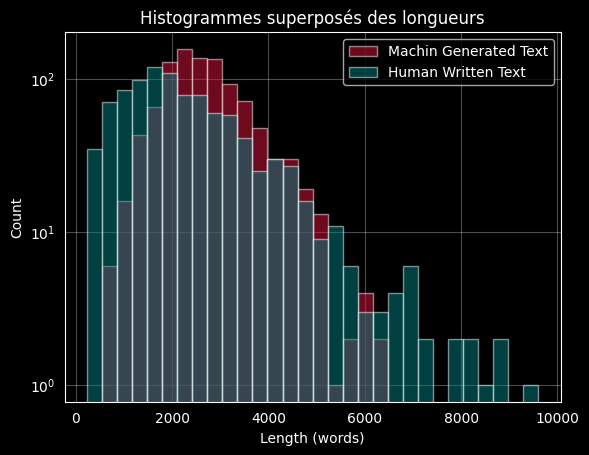

In [8]:
x0 = np.array(basic_auditw["flags_for_label"][0]["length_content"], dtype=float)
x1 = np.array(basic_auditw["flags_for_label"][1]["length_content"], dtype=float)

plot_data_x0 = PlotData(x0, "Human Written Text")
plot_data_x1 = PlotData(x1, "Machin Generated Text")

display_histogram_([plot_data_x1, plot_data_x0])

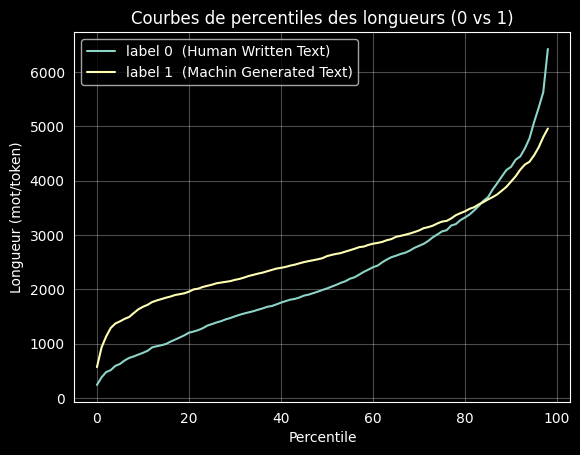

In [9]:
p0 = np.array(basic_auditw["lengths_by_class_words"][0]["p"], dtype=float)
p1 = np.array(basic_auditw["lengths_by_class_words"][1]["p"], dtype=float)

plot_data_p0 = PlotData(p0, "Human Written Text")
plot_data_p1 = PlotData(p1, "Machin Generated Text")

display_percentile([plot_data_p0, plot_data_p1])

## with tokenized dataset

In [10]:
tokenizer= AutoTokenizer.from_pretrained("bert-base-uncased")
dataset_tokenized = AprdbDataset(config={}, keep_meta=True, use_tokenizer=tokenizer)

KeyError: 'split'

In [ ]:
basic_audit_t = basic_audit(dataset_tokenized, tokenized=True)

In [ ]:
p0_t = np.array(basic_audit_t["lengths_by_class_words"][0]["p"], dtype=float)
p1_t = np.array(basic_audit_t["lengths_by_class_words"][1]["p"], dtype=float)

plot_data_p0_t = PlotData(p0_t, "Human Written Text tokenized")
plot_data_p1_t = PlotData(p1_t, "Machin Generated Text tokenized")

display_percentile([plot_data_p0_t, plot_data_p1_t])
display_percentile([plot_data_p0_t, plot_data_p1_t, plot_data_p1, plot_data_p0])

In [ ]:
x0_t = np.array(basic_audit_t["flags_for_label"][0]["length_content"], dtype=float)
x1_t = np.array(basic_audit_t["flags_for_label"][1]["length_content"], dtype=float)

plot_data_x0_t = PlotData(x0_t, "Human Written Text Tokenized")
plot_data_x1_t = PlotData(x1_t, "Machin Generated Text Tokenized")

display_histogram_([plot_data_x1_t, plot_data_x0_t])

In [ ]:
x = dataset_tokenized.data.to_pandas()
x0 = x[x['label']== 0]
x1 = x[x['label'] == 1]

In [ ]:
x0_content = x0['content']
x1_content = x1['content']
print(x0_content)

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

def to_token_str_docs(token_docs):
    # token_docs: List[List[int]] ou List[List[str]]
    # On convertit tout en strings (TF-IDF attend des tokens "textuels")
    return [[str(t) for t in doc] for doc in token_docs]

def tfidf_from_token_lists(tokens0, tokens1, min_df=2, max_df=0.95):
    docs0 = to_token_str_docs(tokens0)
    docs1 = to_token_str_docs(tokens1)

    vec = TfidfVectorizer(
        tokenizer=lambda x: x,
        preprocessor=lambda x: x,
        token_pattern=None,
        min_df=min_df,
        max_df=max_df,
        lowercase=False,
        norm="l2",  # important: normalise -> cosine = dot product
    )

    X = vec.fit_transform(docs0 + docs1)  # sparse matrix
    X0 = X[:len(docs0)]
    X1 = X[len(docs0):]
    return X0, X1

def cosine_metrics_between_sets(X0, X1, sample_pairs=200_000, seed=0, nn_query=10_000):
    rng = np.random.default_rng(seed)

    # A) cosine entre centroïdes (global)
    c0 = X0.mean(axis=0)
    c1 = X1.mean(axis=0)

    # convertir en ndarray 2D (shape = (1, d))
    c0 = np.asarray(c0)
    c1 = np.asarray(c1)
    cos_centroid = float(cosine_similarity(c0, c1)[0, 0])

    # B) moyenne cos inter-classes par sampling de paires
    i0 = rng.integers(0, X0.shape[0], size=sample_pairs)
    i1 = rng.integers(0, X1.shape[0], size=sample_pairs)
    # cosine_similarity accepte sparse; on fait par batch pour limiter RAM
    batch = 20_000
    vals = []
    for start in range(0, sample_pairs, batch):
        a = i0[start:start+batch]
        b = i1[start:start+batch]
        # Similarité paire-à-paire: diag(cos(X0[a], X1[b]))
        S = cosine_similarity(X0[a], X1[b])
        vals.append(np.diag(S))
    mean_cos_inter = float(np.mean(np.concatenate(vals)))

    # C) nearest neighbor : pour un sous-échantillon de X0, max cosine vers X1
    q = min(nn_query, X0.shape[0])
    q_idx = rng.choice(X0.shape[0], size=q, replace=False)

    nn = NearestNeighbors(n_neighbors=1, metric="cosine")  # distance = 1 - cosine
    nn.fit(X1)
    dist, _ = nn.kneighbors(X0[q_idx], n_neighbors=1)
    # dist = 1 - cosine
    mean_nn_cos = float(np.mean(1.0 - dist[:, 0]))

    return {
        "cos_centroid": cos_centroid,
        "mean_cos_inter_sampled": mean_cos_inter,
        "mean_nearest_neighbor_cos_0_to_1": mean_nn_cos,
    }

# ---- Exemple d'usage ----
tokens0 = x0_content.tolist()
tokens1 = x1_content.tolist()
X0, X1 = tfidf_from_token_lists(tokens0, tokens1)
metrics = cosine_metrics_between_sets(X0, X1)
print(metrics)

